# EDA – Queima de lenha nos fornos da fábrica de telhas

Projeto Integrado – Big Data | Fábrica de telhas de barro

- Base: telhas_queimas_limpo.csv (gerada pelo simulador e limpa no R)
- Problema: falta de controle sobre a queima de lenha em cada forno
- Objetivo da EDA: entender o consumo de lenha por forno, por tipo de lenha e por tipo de forno

In [1]:
# Gráficos básicos
import matplotlib.pyplot as plt
# Trabalhar com números
import numpy as np
# Ler e organizar tabelas
import pandas as pd
# Gráficos mais detalhados
import seaborn as sns

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
df = pd.read_csv('/content/drive/MyDrive/Projeto_PI/telhas_queimas_limpo.csv')
df.head()

,id_queima,id_forno,tipo_forno,tipo_lenha_utilizada,quantidade_lenha_utilizada_kg,data_inicio_queima,data_fim_queima,tempo_total_queima_horas,temperatura_forno_c,quantidade_telhas_no_forno,...,quantidade_telhas_produzidas,quantidade_telhas_com_defeito,arquivo_origem,queima_sobreposta,telhas_boas,taxa_defeito_pct,lenha_kg_por_hora,lenha_kg_por_mil_telhas,data_queima,mes_queima
0,Q2026092321491001,F001,Forno Intermitente,Angico,889.6,2026-09-23 21:49:00,2026-09-26 03:01:00,53.2,760,8000,...,8000,541,telhas_queimas_20260923_214910.csv,False,7459,6.7625,16.721805,111.2,2026-09-24,2026-09
1,Q2026092321494601,F001,Forno Intermitente,Aroeira,1535.2,2026-09-23 21:49:00,2026-09-26 04:37:00,54.8,945,8000,...,8000,474,telhas_queimas_20260923_214946.csv,True,7526,5.9250,28.014599,191.9,2026-09-24,2026-09
2,Q2026092321491003,F002,Forno Túnel,Angico,2143.0,2026-09-23 21:49:00,2026-09-25 11:49:00,38.0,893,10000,...,10000,983,telhas_queimas_20260923_214910.csv,False,9017,9.8300,56.394737,214.3,2026-09-24,2026-09
3,Q2026092321494603,F002,Forno Túnel,Pinus,1926.0,2026-09-23 21:49:00,2026-09-26 19:25:00,69.6,893,10000,...,10000,627,telhas_queimas_20260923_214946.csv,True,9373,6.2700,27.672414,192.6,2026-09-24,2026-09
4,Q2026092321491005,F003,Forno Intermitente,Aroeira,1510.4,2026-09-23 21:49:00,2026-09-25 19:37:00,45.8,975,8000,...,8000,389,telhas_queimas_20260923_214910.csv,False,7611,4.8625,32.978166,188.8,2026-09-24,2026-09


# 2. Estrutura e qualidade dos dados.

In [5]:
print(df.shape)  # (linhas, colunas)
df.info()  # tipo e quantidade de valores de cada coluna

(624, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 624 entries, 0 to 623
Data columns (total 22 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_queima                      624 non-null    object 
 1   id_forno                       624 non-null    object 
 2   tipo_forno                     624 non-null    object 
 3   tipo_lenha_utilizada           624 non-null    object 
 4   quantidade_lenha_utilizada_kg  624 non-null    float64
 5   data_inicio_queima             624 non-null    object 
 6   data_fim_queima                624 non-null    object 
 7   tempo_total_queima_horas       624 non-null    float64
 8   temperatura_forno_c            624 non-null    int64  
 9   quantidade_telhas_no_forno     624 non-null    int64  
 10  responsavel_queima             624 non-null    object 
 11  id_lote                        624 non-null    object 
 12  quantidade_telhas_produzidas   624 non-n

In [6]:
#Converter as datas
df['data_inicio_queima'] = pd.to_datetime(df['data_inicio_queima'])
df['data_fim_queima'] = pd.to_datetime(df['data_fim_queima'])
df['data_queima'] = pd.to_datetime(df['data_queima'])
df.dtypes  # confere se as datas viraram datetime

,0
id_queima,object
id_forno,object
tipo_forno,object
tipo_lenha_utilizada,object
quantidade_lenha_utilizada_kg,float64
data_inicio_queima,datetime64[ns]
data_fim_queima,datetime64[ns]
tempo_total_queima_horas,float64
temperatura_forno_c,int64
quantidade_telhas_no_forno,int64


### Decisões de limpeza

A limpeza foi feita antes, no RStudio (notebook `limpeza_telhas.Rmd`). Lá foram feitas a validação dos valores, as checagens de consistência, a verificação de repetidos e a criação das variáveis novas. Nenhum registro foi removido, porque os dados vêm de um simulador e já saíram bem formados.

No Colab, só confirmamos que não há nulos nem duplicados (0 e 0) e convertemos as colunas de data de texto para data e hora.

In [7]:
#Validação dos dados limpos no Studio R
print(df.isnull().sum())  # valores nulos por coluna
print(df.duplicated().sum())  # linhas duplicadas
print(df['id_queima'].duplicated().sum())  # ids de queima repetidos

id_queima                        0
id_forno                         0
tipo_forno                       0
tipo_lenha_utilizada             0
quantidade_lenha_utilizada_kg    0
data_inicio_queima               0
data_fim_queima                  0
tempo_total_queima_horas         0
temperatura_forno_c              0
quantidade_telhas_no_forno       0
responsavel_queima               0
id_lote                          0
quantidade_telhas_produzidas     0
quantidade_telhas_com_defeito    0
arquivo_origem                   0
queima_sobreposta                0
telhas_boas                      0
taxa_defeito_pct                 0
lenha_kg_por_hora                0
lenha_kg_por_mil_telhas          0
data_queima                      0
mes_queima                       0
dtype: int64
0
0


## 3. Estatística descritiva.

In [8]:
colunas_num = [
    'quantidade_lenha_utilizada_kg',
    'tempo_total_queima_horas',
    'temperatura_forno_c',
    'quantidade_telhas_no_forno',
    'quantidade_telhas_com_defeito',
    'taxa_defeito_pct',
    'lenha_kg_por_hora',
    'lenha_kg_por_mil_telhas'
]
df[colunas_num].describe().round(2)  # estatística descri

,quantidade_lenha_utilizada_kg,tempo_total_queima_horas,temperatura_forno_c,quantidade_telhas_no_forno,quantidade_telhas_com_defeito,taxa_defeito_pct,lenha_kg_por_hora,lenha_kg_por_mil_telhas
count,624.00,624.00,624.00,624.00,624.00,624.00,624.00,624.00
mean,1769.07,45.47,861.56,11333.33,679.58,5.96,44.70,155.21
std,796.20,15.46,67.14,4030.91,468.28,3.26,28.03,36.77
min,728.00,18.40,750.00,8000.00,44.00,0.55,10.31,90.10
25%,1179.50,32.30,801.00,8000.00,320.00,3.08,24.28,124.95
50%,1555.20,45.60,857.00,10000.00,586.00,5.93,37.05,157.45
75%,2118.15,58.72,919.00,13500.00,887.00,8.57,56.41,186.02
max,3960.00,72.00,980.00,18000.00,2130.00,11.92,201.20,220.00


### Interpretação da estatística descritiva

- Cada queima usa em média 1.769 kg de lenha, mas a mediana é 1.555 kg. Como a média é maior que a mediana, existem queimas grandes que puxam a média para cima.
- O tempo de queima varia de 18 a 72 horas (média de 45 horas) e a temperatura fica entre 750 e 980 °C.
- A taxa de defeito média é de 6%, variando de 0,55% a 11,9%.
- A lenha por mil telhas varia de 90 a 220 kg (média de 155 kg). Essa medida é a mais justa para comparar queimas de tamanhos diferentes.

In [9]:
#Contagem das variaveis de categoria
print(df['tipo_forno'].value_counts())  # queimas por tipo de forno
print(df['tipo_lenha_utilizada'].value_counts())  # queimas por tipo de lenha
print(df['id_forno'].value_counts())  # queimas por forno
print(df['responsavel_queima'].value_counts())  # queimas por responsável

tipo_forno
Forno Intermitente    260
Forno Túnel           208
Forno Caieira         156
Name: count, dtype: int64
tipo_lenha_utilizada
Aroeira               139
Pinus                 134
Angico                119
Eucalipto             116
Resíduo de Madeira    116
Name: count, dtype: int64
id_forno
F001    52
F002    52
F003    52
F004    52
F005    52
F006    52
F007    52
F008    52
F009    52
F010    52
F011    52
F012    52
Name: count, dtype: int64
responsavel_queima
Davi Miguel    71
Eloá           71
Emanuel        67
Ravi Lucca     63
Guilherme      63
Rafael         63
Caleb          61
Amanda         59
Matheus        54
Ana Beatriz    52
Name: count, dtype: int64


In [10]:
#Aviso sobre as datas
print(df['data_inicio_queima'].nunique())  # quantos inícios diferentes existem
print(df['queima_sobreposta'].value_counts())  # quantas queimas se sobrepõem

3
queima_sobreposta
True     600
False     24
Name: count, dtype: int64


### Limitação: datas

Os dados têm só 3 horários de início diferentes, porque o simulador usa a hora em que roda como início da queima. Por isso 600 das 624 queimas aparecem como sobrepostas (o mesmo forno começando antes de terminar a queima anterior). Isso não acontece numa fábrica real.

Por causa disso, **não fazemos análise por data ou por mês** nesta EDA. As análises por forno, tipo de lenha, tipo de forno e responsável continuam válidas.

## 4. Visualizações

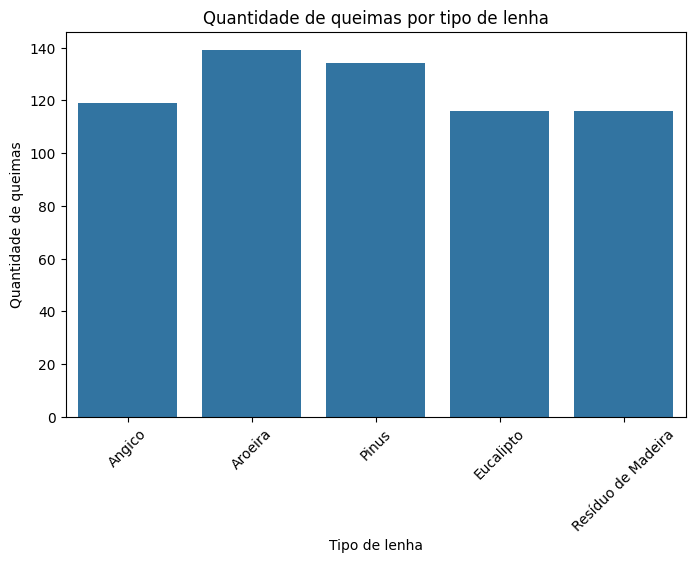

In [11]:
#Queimas por tipo de lenha (gráfico de contagem)
plt.figure(figsize=(8, 5))
sns.countplot(x='tipo_lenha_utilizada', data=df)
plt.title('Quantidade de queimas por tipo de lenha')
plt.xlabel('Tipo de lenha')
plt.ylabel('Quantidade de queimas')
plt.xticks(rotation=45)
plt.show()


**Interpretação:** as cinco lenhas são usadas de forma parecida. Aroeira (139 queimas) e Pinus (134) são as mais usadas, e Eucalipto e Resíduo de Madeira (116 cada) as menos usadas. Não há uma lenha dominante, então dá para comparar o consumo entre elas com amostras de tamanho parecido.

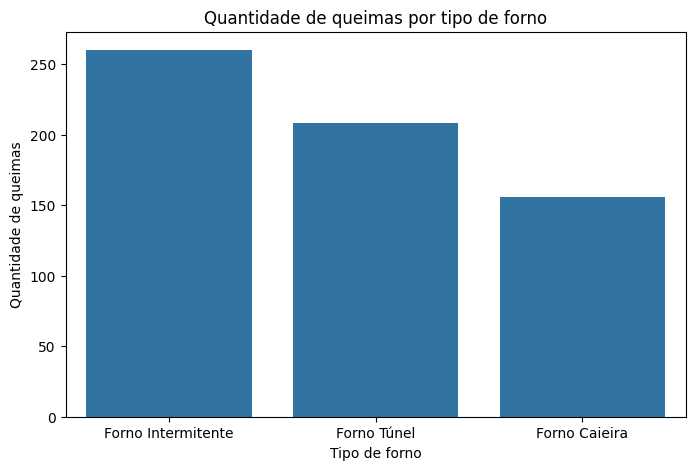

In [12]:
#Queimas por tipo de forno
plt.figure(figsize=(8, 5))
sns.countplot(x='tipo_forno', data=df)
plt.title('Quantidade de queimas por tipo de forno')
plt.xlabel('Tipo de forno')
plt.ylabel('Quantidade de queimas')
plt.show()

**Interpretação:** o forno Intermitente tem mais queimas (260, cerca de 42%), seguido do Túnel (208, 33%) e do Caieira (156, 25%). Isso acontece porque a fábrica tem 5 fornos intermitentes, 4 de túnel e 3 caieira, e cada forno tem 52 queimas.

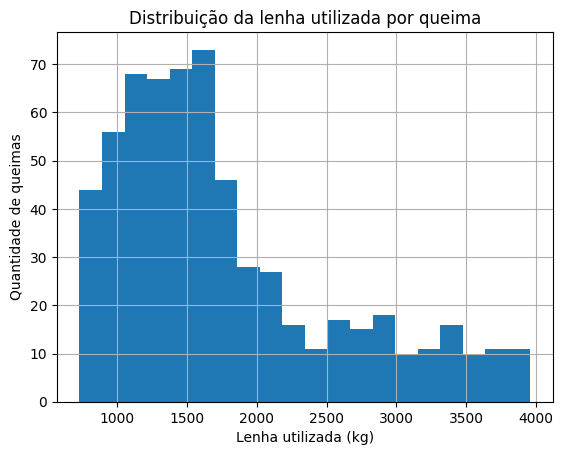

In [13]:
#Distribuição da lenha por queima (histograma)
df['quantidade_lenha_utilizada_kg'].hist(bins=20)
plt.title('Distribuição da lenha utilizada por queima')
plt.xlabel('Lenha utilizada (kg)')
plt.ylabel('Quantidade de queimas')
plt.show()

**Interpretação:** quase metade das queimas (47%) usa entre 1.000 e 1.700 kg de lenha, e o número de queimas cai bastante a partir de 2.000 kg. Há uma cauda longa até cerca de 4.000 kg (distribuição assimétrica à direita). Essa cauda é formada pelas queimas dos fornos maiores.

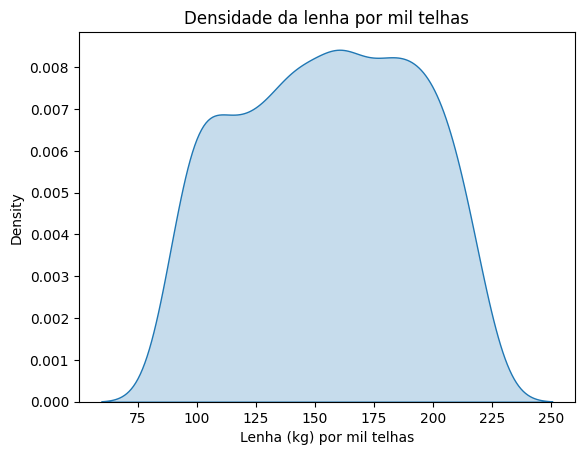

In [14]:
#Densidade da lenha por mil telhas
sns.kdeplot(df['lenha_kg_por_mil_telhas'], fill=True)
plt.title('Densidade da lenha por mil telhas')
plt.xlabel('Lenha (kg) por mil telhas')
plt.show()

**Interpretação:** a lenha por mil telhas vai de 90 a 220 kg e não tem um pico claro: a curva é larga, com a maior parte dos valores entre cerca de 100 e 210 kg. Ou seja, para a mesma quantidade de telhas, o gasto de lenha muda muito de uma queima para outra. Esse é o ponto central do problema do projeto (falta de controle da queima de lenha).

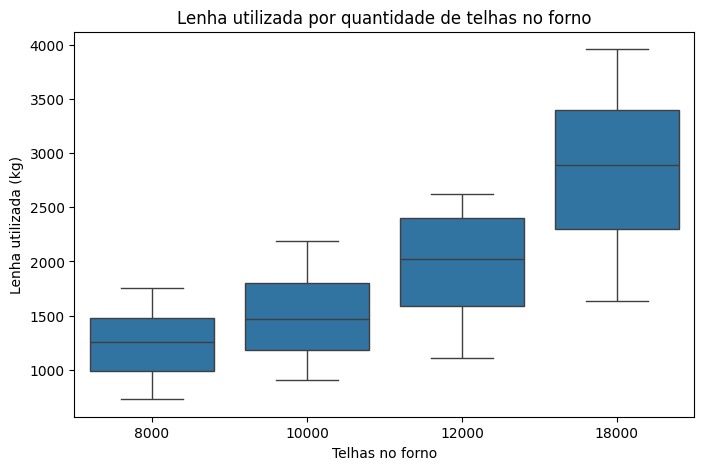

In [15]:
#Lenha pelo tamanho da carga do forno
plt.figure(figsize=(8, 5))
sns.boxplot(x='quantidade_telhas_no_forno', y='quantidade_lenha_utilizada_kg', data=df)
plt.title('Lenha utilizada por quantidade de telhas no forno')
plt.xlabel('Telhas no forno')
plt.ylabel('Lenha utilizada (kg)')
plt.show()

**Interpretação:** a lenha cresce junto com a quantidade de telhas no forno. A mediana vai de cerca de 1.260 kg (8.000 telhas) para 1.470 kg (10.000), 2.020 kg (12.000) e 2.890 kg (18.000). Isso explica a cauda do histograma: as queimas de 18 mil telhas são as que mais gastam lenha, e não são um erro. Por isso, para comparar fornos de tamanhos diferentes, usamos a lenha por mil telhas.

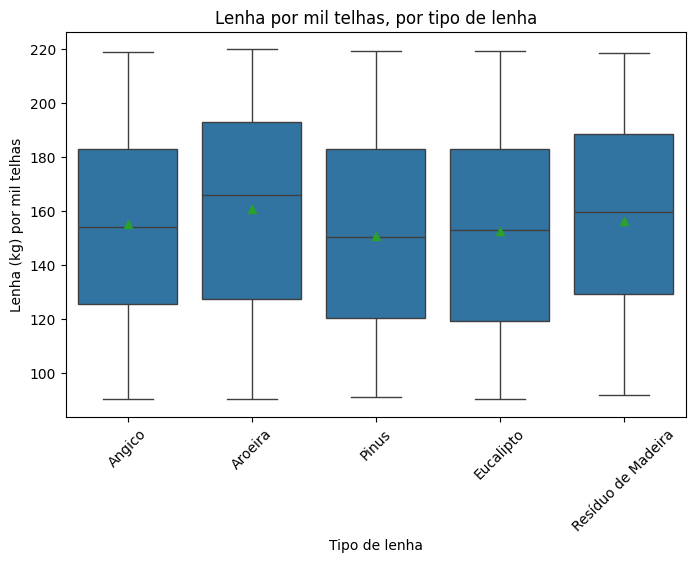

In [16]:
#Lenha por mil telhas, por tipo de lenha
plt.figure(figsize=(8, 5))
sns.boxplot(x='tipo_lenha_utilizada', y='lenha_kg_por_mil_telhas', data=df, showmeans=True)
plt.title('Lenha por mil telhas, por tipo de lenha')
plt.xlabel('Tipo de lenha')
plt.ylabel('Lenha (kg) por mil telhas')
plt.xticks(rotation=45)
plt.show()

**Interpretação:** as médias ficam entre 151 kg/mil telhas (Pinus) e 161 kg/mil telhas (Aroeira), uma diferença de cerca de 10 kg. Como as caixas se sobrepõem quase por completo, não dá para dizer que uma lenha rende claramente mais que outra nestes dados. A variação dentro de cada lenha (de 90 a 220 kg) é muito maior que a diferença entre elas.

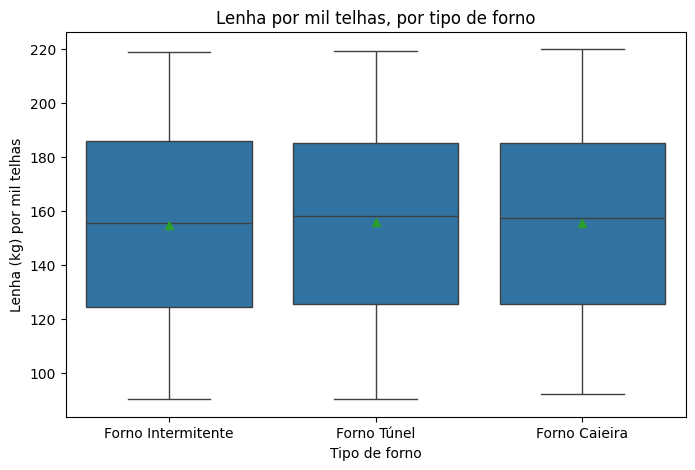

In [17]:
#Lenha por mil telhas, por tipo de forno
plt.figure(figsize=(8, 5))
sns.boxplot(x='tipo_forno', y='lenha_kg_por_mil_telhas', data=df, showmeans=True)
plt.title('Lenha por mil telhas, por tipo de forno')
plt.xlabel('Tipo de forno')
plt.ylabel('Lenha (kg) por mil telhas')
plt.show()

**Interpretação:** os três tipos de forno têm praticamente a mesma média de lenha por mil telhas (Intermitente 154,7, Caieira 155,4 e Túnel 155,7 kg). O tipo de forno não muda o consumo nestes dados.

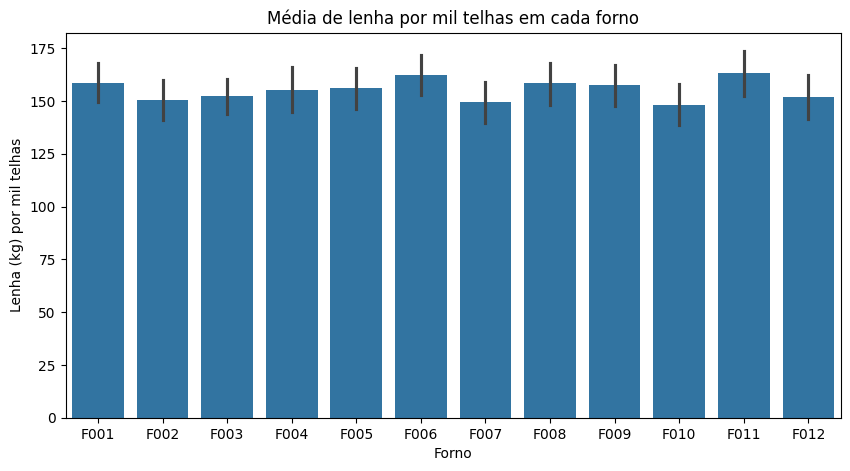

In [18]:
#Lenha por mil telhas em cada forno
plt.figure(figsize=(10, 5))
sns.barplot(x='id_forno', y='lenha_kg_por_mil_telhas', data=df)
plt.title('Média de lenha por mil telhas em cada forno')
plt.xlabel('Forno')
plt.ylabel('Lenha (kg) por mil telhas')
plt.show()

**Interpretação:** as médias dos 12 fornos ficam entre 148 kg/mil telhas (F010) e 163 kg/mil telhas (F011). As linhas pretas se sobrepõem, então nenhum forno se destaca claramente como o que mais ou o que menos gasta lenha por telha.

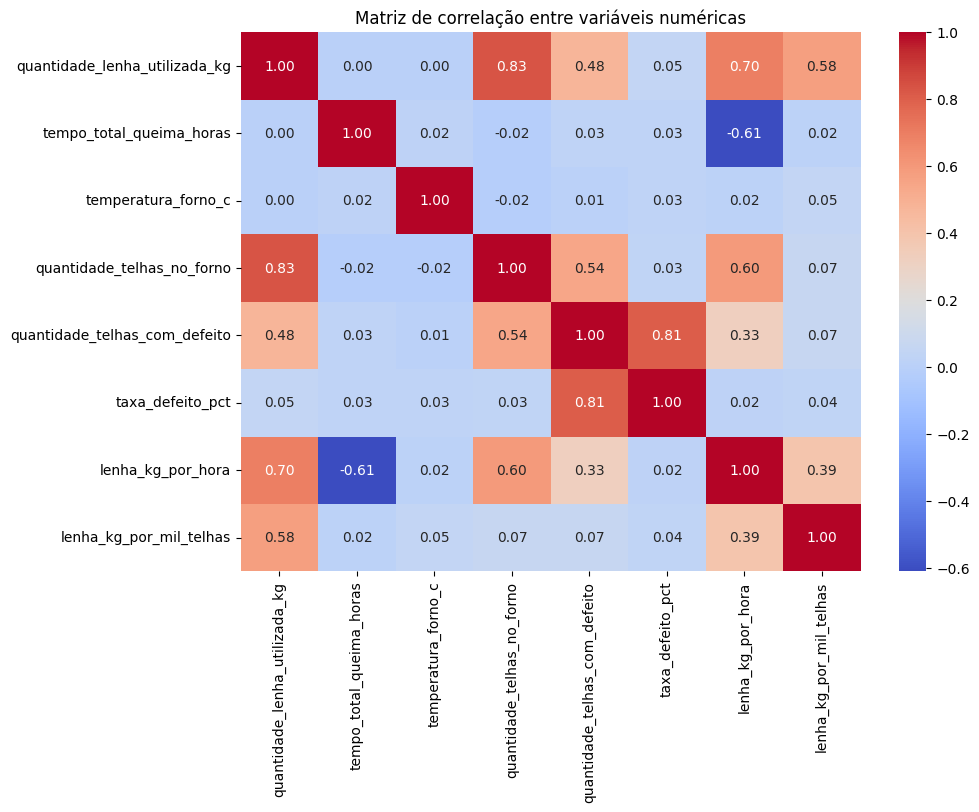

In [19]:
#Mapa de calor das correlações
corr = df[colunas_num].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de correlação entre variáveis numéricas')
plt.show()

**Interpretação:**

- A lenha usada tem correlação forte com a quantidade de telhas no forno (0,83): quanto maior a carga, mais lenha.
- A lenha não tem relação com o tempo de queima (0,00) nem com a temperatura (0,00) nestes dados.
- A taxa de defeito não tem relação com nenhuma variável do processo (todas ficam em 0,05 ou menos).
- Algumas correlações altas são só consequência da conta que criou a variável. Exemplos: telhas com defeito e taxa de defeito (0,81), e tempo e lenha por hora (–0,61), porque a lenha por hora é a lenha dividida pelo tempo.
- Numa queima real, esperaríamos que tempo e temperatura influenciassem o consumo. Aqui isso não aparece porque os dados são simulados.

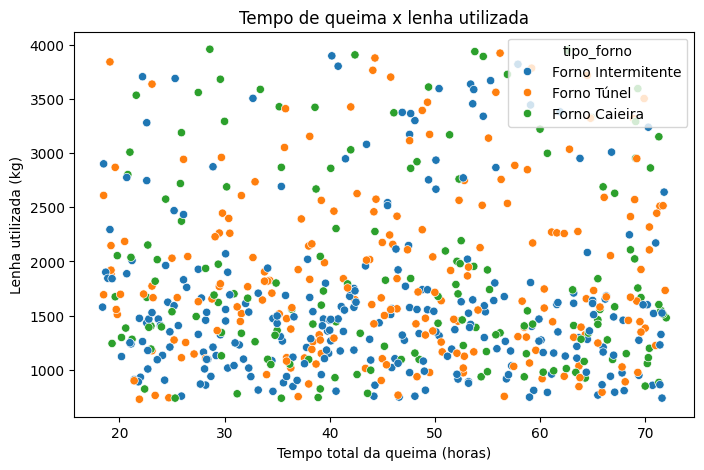

In [20]:
#tempo de queima x lenha (dispersão)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='tempo_total_queima_horas', y='quantidade_lenha_utilizada_kg', hue='tipo_forno')
plt.title('Tempo de queima x lenha utilizada')
plt.xlabel('Tempo total da queima (horas)')
plt.ylabel('Lenha utilizada (kg)')
plt.show()

**Interpretação:** os pontos formam uma nuvem sem direção: queimas mais longas não gastam mais lenha. As cores dos três tipos de forno ficam misturadas, então o tipo de forno também não separa o consumo. Isso confirma a correlação de 0,00 do mapa de calor.

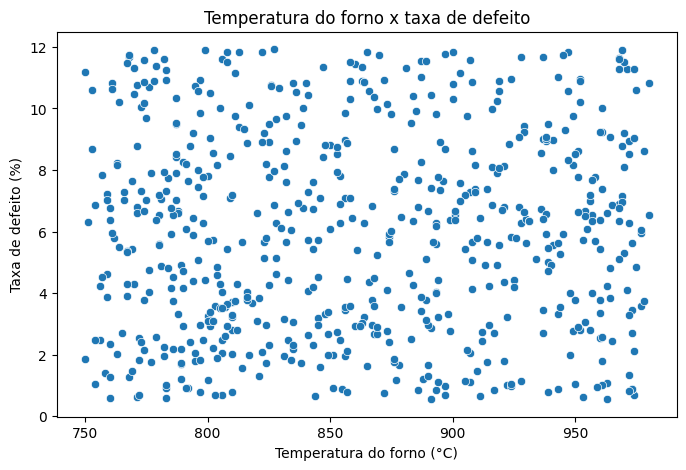

In [21]:
#Temperatura x taxa de defeito
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='temperatura_forno_c', y='taxa_defeito_pct')
plt.title('Temperatura do forno x taxa de defeito')
plt.xlabel('Temperatura do forno (°C)')
plt.ylabel('Taxa de defeito (%)')
plt.show()

**Interpretação:** não aparece nenhum padrão. A taxa de defeito varia de 0,5% a 12% em todas as temperaturas, de 750 a 980 °C. Nestes dados, a temperatura não explica os defeitos.

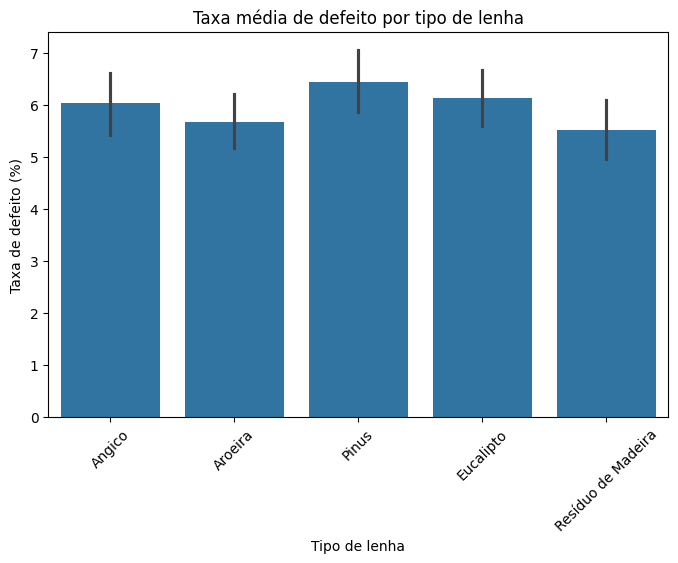

In [22]:
#Taxa de defeito por tipo de lenha
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='tipo_lenha_utilizada', y='taxa_defeito_pct')
plt.title('Taxa média de defeito por tipo de lenha')
plt.xlabel('Tipo de lenha')
plt.ylabel('Taxa de defeito (%)')
plt.xticks(rotation=45)
plt.show()

**Interpretação:** a taxa média de defeito vai de 5,5% (Resíduo de Madeira) a 6,4% (Pinus), uma diferença de menos de 1 ponto percentual. As linhas de incerteza se sobrepõem, então não dá para afirmar que alguma lenha produza mais defeito que outra.

## 5. Tabelas-resumo


In [23]:
#tipo de forno x tipo de lenha
print(pd.crosstab(df['tipo_forno'], df['tipo_lenha_utilizada']))

tipo_lenha_utilizada  Angico  Aroeira  Eucalipto  Pinus  Resíduo de Madeira
tipo_forno                                                                 
Forno Caieira             32       37         29     35                  23
Forno Intermitente        50       58         51     45                  56
Forno Túnel               37       44         36     54                  37


**Interpretação:** todos os tipos de forno usam todos os tipos de lenha (de 23 a 58 queimas em cada combinação). Por isso dá para comparar as lenhas dentro de cada tipo de forno, sem que um tipo de lenha fique restrito a um só forno.

In [24]:
#Resumo por forno
resumo_forno = df.groupby(['id_forno', 'tipo_forno']).agg(
    queimas=('id_queima', 'count'),
    lenha_total_kg=('quantidade_lenha_utilizada_kg', 'sum'),
    kg_por_mil_telhas=('lenha_kg_por_mil_telhas', 'mean'),
    defeito_medio_pct=('taxa_defeito_pct', 'mean')
).round(2).sort_values('lenha_total_kg', ascending=False)
resumo_forno

,,queimas,lenha_total_kg,kg_por_mil_telhas,defeito_medio_pct
id_forno,tipo_forno,,,,
F006,Forno Caieira,52,151821.0,162.20,6.47
F008,Forno Intermitente,52,148138.2,158.27,5.94
F009,Forno Túnel,52,147535.2,157.62,5.94
F011,Forno Túnel,52,101751.6,163.06,5.91
F002,Forno Túnel,52,78218.0,150.42,5.64
F007,Forno Intermitente,52,77626.0,149.28,6.61
F010,Forno Caieira,52,77009.0,148.09,5.89
F001,Forno Intermitente,52,65981.6,158.61,5.58
F005,Forno Caieira,52,64852.8,155.90,6.12


**Interpretação:** os três fornos que mais gastam lenha no total (F006, F008 e F009, entre 147 mil e 152 mil kg) são os de 18 mil telhas por queima. Os que menos gastam (F012, F003 e F004, cerca de 63 mil a 65 mil kg) são os de 8 mil telhas. O total depende do tamanho do forno. Na lenha por mil telhas os fornos ficam muito próximos (de 148 a 163 kg), então a comparação justa entre fornos é por essa medida.

In [25]:
 #Resumo por tipo de lenha
resumo_lenha = df.groupby('tipo_lenha_utilizada').agg(
    queimas=('id_queima', 'count'),
    lenha_total_kg=('quantidade_lenha_utilizada_kg', 'sum'),
    kg_por_mil_telhas=('lenha_kg_por_mil_telhas', 'mean'),
    kg_por_hora=('lenha_kg_por_hora', 'mean'),
    defeito_medio_pct=('taxa_defeito_pct', 'mean')
).round(2).sort_values('kg_por_mil_telhas')
resumo_lenha

,queimas,lenha_total_kg,kg_por_mil_telhas,kg_por_hora,defeito_medio_pct
tipo_lenha_utilizada,,,,,
Pinus,134,217108.8,150.69,41.50,6.44
Eucalipto,116,207170.6,152.58,43.33,6.12
Angico,119,209952.8,155.27,43.81,6.03
Resíduo de Madeira,116,217442.0,156.23,49.40,5.51
Aroeira,139,252224.8,160.86,45.78,5.68


**Interpretação:** o Pinus rende um pouco mais (150,7 kg por mil telhas) e a Aroeira um pouco menos (160,9 kg). A Aroeira tem o maior total de lenha porque também tem mais queimas (139). As diferenças entre as lenhas são pequenas (cerca de 10 kg por mil telhas, ou 7%) e ficam dentro da variação normal das queimas, então servem como ponto de partida e não como conclusão.

## 6. Insights finais e limitações

### Principais achados

1. **O total de lenha depende do tamanho do forno.** As queimas de 18 mil telhas têm mediana de cerca de 2.890 kg de lenha, contra cerca de 1.260 kg nas de 8 mil telhas (correlação de 0,83). Os três fornos que mais gastam (F006, F008 e F009) são os maiores.
2. **Para comparar queimas, a medida certa é a lenha por mil telhas.** Ela fica em média em 155 kg, e os 12 fornos têm médias parecidas (de 148 a 163 kg).
3. **O mesmo forno gasta valores muito diferentes de uma queima para outra.** Em todos os fornos a lenha por mil telhas vai de cerca de 90 a 220 kg, ou seja, algumas queimas gastam mais que o dobro de lenha que outras para a mesma quantidade de telhas. Cerca de 14% das queimas (85) ficaram entre 200 e 220 kg por mil telhas. Esse é o ponto de atenção ligado ao problema do projeto: a falta de controle da queima de lenha.
4. **Tipo de lenha, tipo de forno, tempo e temperatura não explicaram o consumo nestes dados.** As diferenças entre as lenhas são pequenas (de 151 a 161 kg por mil telhas) e ficam dentro da variação normal. Tempo e temperatura têm correlação 0,00 com a lenha.
5. **A taxa de defeito é de cerca de 6% e não tem relação clara** com temperatura, tempo ou tipo de lenha.

### Como isso ajuda na decisão

- Acompanhar a lenha por mil telhas em cada queima, e não só o total, para comparar fornos de tamanhos diferentes.
- Definir um valor de alerta (por exemplo, acima de 200 kg por mil telhas) para investigar as queimas que gastaram demais.
- Registrar mais informações de cada queima (como umidade da lenha e condições do dia) para descobrir o que faz o consumo variar tanto.

### Limitações

- Os dados são **simulados**, por isso não têm relação real entre lenha, tempo e temperatura, como teríamos numa fábrica de verdade.
- Existem só 3 horários de início diferentes e 600 das 624 queimas se sobrepõem no mesmo forno, então não fizemos análise por data.
- Cada forno tem sempre o mesmo tamanho de carga, e as telhas produzidas são sempre iguais às que entraram no forno.
- A base tem 624 registros, é pequena e acadêmica. A mesma estrutura de análise pode ser aplicada a um volume maior.